# Assignment 4: logistic regression (Daniel)
L1 (lasso) logistic regression on the 89 anterior cingulate libraries from Assignment 3.
The L1 penalty sets most gene weights to zero, so the genes left over are the model's signature (needed for step 5).

In [7]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")  # hides scikit-learn deprecation messages

## Step 1: load the data from Assignment 2 (same samples and filtering as Assignment 3)

In [3]:
expr = pd.read_csv("data/expr_by_library.tsv.gz", sep="\t", index_col=0)
meta = pd.read_csv("data/meta_by_library.tsv", sep="\t", index_col=0)

meta = meta[meta.region == "ancg"]                 # 89 anterior cingulate libraries
log_expr = np.log2(expr[meta.index] + 1)
log_expr = log_expr[log_expr.median(axis=1) > 0]   # drop genes that are basically off
genes_by_variance = log_expr.var(axis=1).sort_values(ascending=False).index

In [5]:
sl = meta.index.str.extract(r"SL(\d+)")[0].astype(int).values
meta["batch"] = np.where(sl > 20000, "B", "A")

keep = meta[(meta.region == "ancg")].copy()
keep["group"] = np.where(keep.dx == "control", "Control", "Disorder")

#log scale and filter genes with zero expression (about 8000) before doing plots
log_expr = np.log2(expr[keep.index] + 1)
log_expr = log_expr[log_expr.median(axis=1) > 0]

#select 5000 most variable genes 
top = log_expr.var(axis=1).sort_values(ascending=False).index[:5000]
X = log_expr.loc[top].T
labels=keep['group'].tolist()

#extract clustering labels from assignment 3 (rerun since i didnt save them)
from sklearn.cluster import KMeans

kmeans=KMeans(n_clusters=2,
              random_state=0,
              n_init="auto")
cluster_labels=kmeans.fit_predict(X)

## Step 2: the two things to predict
- **group** (Assignment 1): 1 = any disorder, 0 = control
- **cluster** (my Assignment 3 hierarchical clustering, k = 2): 1 = the 15 library subgroup, 0 = the other 74.
  With only two clusters, "one cluster vs all others" is just subgroup vs rest.

In [11]:
cluster_labels
cluster_labels = pd.Series(
    cluster_labels,
    index=meta.index,
    name="cluster",
)

In [12]:
subgroup = cluster_labels.value_counts().idxmin()        # the smaller cluster

y = {
    "group": (meta.dx != "control").astype(int),
    "cluster": (cluster_labels == subgroup).astype(int),
}
print(y["group"].value_counts(), y["cluster"].value_counts())

dx
1    67
0    22
Name: count, dtype: int64 cluster
0    75
1    14
Name: count, dtype: int64


## Steps 2 and 4: train with 10 to 10,000 genes
`cross_val_predict` splits the libraries into 5 folds and predicts each fold with a model trained on the other 4,
so every library is predicted by a model that never saw it. C = 0.1 sets how strong the L1 penalty is.

In [18]:
def make_model():
    return make_pipeline(
        StandardScaler(),
        SVC(probability=True, kernel="linear"),
    )

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
predictions = pd.DataFrame(index=meta.index)
auc_rows = []

for n in [10, 100, 1000, 5000, 10000]:
    X = log_expr.loc[genes_by_variance[:n]].T      # rows = libraries, columns = genes
    for target in ["group", "cluster"]:
        prob = cross_val_predict(make_model(), X, y[target], cv=cv, method="predict_proba")[:, 1]
        predictions[f"{target}_pred_g{n}"] = (prob >= 0.5).astype(int)
        auc_rows.append({"genes": n, "target": target, "AUC": roc_auc_score(y[target], prob)})

auc = pd.DataFrame(auc_rows)
auc.to_csv("results/a4_svm_auc.tsv", sep="\t", index=False)
predictions.to_csv("results/a4_predictions_svm.tsv", sep="\t")
auc.pivot(index="genes", columns="target", values="AUC").round(3)

target,cluster,group
genes,,
10,0.956,0.400
100,0.999,0.566
1000,1.000,0.450
5000,1.000,0.577
10000,1.000,0.543


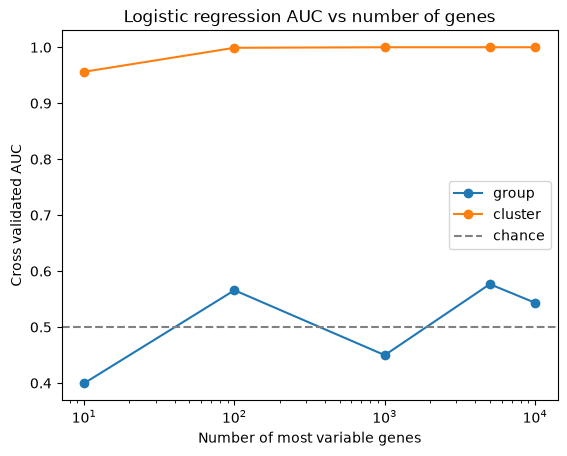

In [19]:
for target in ["group", "cluster"]:
    d = auc[auc.target == target]
    plt.plot(d.genes, d.AUC, marker="o", label=target)
plt.axhline(0.5, color="gray", linestyle="--", label="chance")
plt.xscale("log")
plt.xlabel("Number of most variable genes")
plt.ylabel("Cross validated AUC")
plt.title("Logistic regression AUC vs number of genes")
plt.legend()
plt.savefig("plots/a4_logreg_auc_by_genes.png", dpi=200, bbox_inches="tight")
plt.show()

## Signature genes for the step 5 heatmap
Fit each model on all 89 libraries with 5,000 genes and keep the genes with a nonzero weight.

In [21]:
symbols = pd.read_csv("gene_symbols.tsv", sep="\t", index_col=0)["symbol"]
X = log_expr.loc[genes_by_variance[:5000]].T
rows = []
for target in ["group", "cluster"]:
    weights = make_model().fit(X, y[target])[-1].coef_[0]
    for gene, w in zip(X.columns, weights):
        if w != 0:
            rows.append({"gene": gene, "symbol": symbols.get(gene), "coef": w, "target": target, "method": "svm"})

signature = pd.DataFrame(rows)
signature.to_csv("results/a4_signature_svm.tsv", sep="\t", index=False)
signature.groupby("target").size()

target
cluster    5000
group      5000
dtype: int64